# Top 10 Most Broadly Active Compounds — Structural Analysis

10 compounds active across the most cell lines (6–10 out of 14).  
**Question:** Do they share a common chemical skeleton, or does the same broad behavior arise from unrelated structures?

In [35]:
import requests

import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.manifold import TSNE

from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFMCS
from rdkit.Chem import rdFingerprintGenerator
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
print('Ready.')

Ready.


## Step 1 — Load Data

In [25]:
TOP10_CIDS = [11057, 5288209, 2724411, 62770, 457193, 108005, 443939, 2723598, 19042, 5284469]

# ── SMILES from local cleaned datasets (as before) ────────────────────────────
smi1 = pd.read_csv(BASE + 'cleaned_datasets/combined_hepg2_casepase.csv',
                   usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
smi2 = pd.read_csv(BASE + 'cleaned_datasets/AID_1346980_cleaned.csv',
                   usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
smiles_df = (pd.concat([smi1, smi2])
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID'))

# ── IUPAC names from PubChem PUG REST ────────────────────────────────────────
cid_str = ','.join(str(c) for c in TOP10_CIDS)
url = (f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid_str}'
       f'/property/IUPACName/JSON')
resp = requests.get(url, timeout=30)
resp.raise_for_status()
name_df = pd.DataFrame(resp.json()['PropertyTable']['Properties']).rename(
    columns={'CID': 'PUBCHEM_CID'}
)

# ── Main activity table ───────────────────────────────────────────────────────
adf = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')

assay_cols = [c for c in adf.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]
adf['n_active'] = (adf[assay_cols] == 'Active').sum(axis=1)

df = (adf[adf['PUBCHEM_CID'].isin(TOP10_CIDS)]
      .merge(smiles_df, on='PUBCHEM_CID', how='left')
      .merge(name_df,   on='PUBCHEM_CID', how='left'))

df['mol'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None
)
df = df[df['mol'].notna()].reset_index(drop=True)
df['fp'] = df['mol'].apply(gen.GetFingerprint)

print(f'Loaded {len(df)} compounds')
print(df[['PUBCHEM_CID', 'IUPACName', 'n_active']].sort_values('n_active', ascending=False).to_string(index=False))

Loaded 10 compounds
 PUBCHEM_CID                                                                                                                                                                                                IUPACName  n_active
       11057                                                                                                       [4-[bis[4-(dimethylamino)phenyl]methylidene]cyclohexa-2,5-dien-1-ylidene]-dimethylazanium chloride        10
     5288209                                                                                               (2E,4E,6E,8E)-N-(4-hydroxyphenyl)-3,7-dimethyl-9-(2,6,6-trimethylcyclohexen-1-yl)nona-2,4,6,8-tetraenamide        10
     2724411                                                               bis([4-[[4-(dimethylamino)phenyl]-phenylmethylidene]cyclohexa-2,5-dien-1-ylidene]-dimethylazanium);bis(2-hydroxy-2-oxoacetate);oxalic acid         9
       62770                                                 (7S,9S)-9-acetyl-7-[(2R

## Top-10 Broadly Active Compounds — Summary Table

Rank,CID,Structure,Active / 14,Active Cell Lines
1,11057,,10,"CHO-K1, SH-SY5Y, BJ, MRC-5, Mesangial, SK-N-SH, H-4-II-E, NIH 3T3, Renal Prox. Tubule, HepG2"
2,5288209,,10,"Jurkat, HUV-EC-C, MRC-5, Mesangial, SK-N-SH, H-4-II-E, HEK293, N2a, Renal Prox. Tubule, HepG2"
3,2724411,,9,"CHO-K1, Mesangial, SK-N-SH, H-4-II-E, HEK293, N2a, NIH 3T3, Renal Prox. Tubule, HepG2"
4,62770,,8,"CHO-K1, Jurkat, MRC-5, SK-N-SH, H-4-II-E, N2a, NIH 3T3, HepG2"
5,457193,,7,"CHO-K1, Jurkat, SK-N-SH, H-4-II-E, N2a, NIH 3T3, HepG2"
6,108005,,7,"Jurkat, BJ, MRC-5, SK-N-SH, NIH 3T3, Renal Prox. Tubule, HepG2"
7,443939,,7,"Jurkat, SH-SY5Y, SK-N-SH, H-4-II-E, N2a, NIH 3T3, HepG2"
8,2723598,,6,"CHO-K1, Jurkat, SH-SY5Y, H-4-II-E, NIH 3T3, HepG2"
9,19042,,6,"CHO-K1, Jurkat, SH-SY5Y, SK-N-SH, N2a, HepG2"
10,5284469,,6,"CHO-K1, SH-SY5Y, BJ, SK-N-SH, HEK293, HepG2"

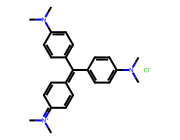
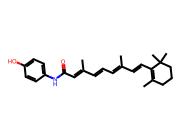
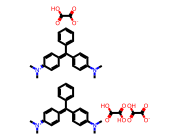
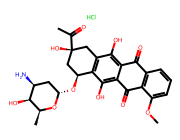
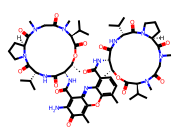
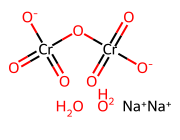
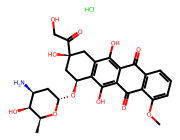
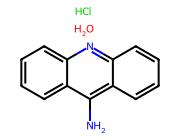
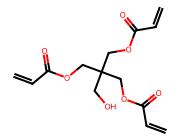
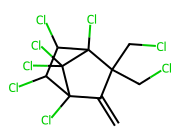

In [26]:
import base64, io
from rdkit.Chem import Draw
from IPython.display import HTML

CELL_LINE_MAP = {
    'AID_1346980': 'CHO-K1',
    'AID_655':     'Jurkat',
    'AID_656':     'HUV-EC-C',
    'AID_657':     'SH-SY5Y',
    'AID_658':     'BJ',
    'AID_659':     'MRC-5',
    'AID_660':     'Mesangial',
    'AID_661':     'SK-N-SH',
    'AID_663':     'H-4-II-E',
    'AID_664':     'HEK293',
    'AID_665':     'N2a',
    'AID_666':     'NIH 3T3',
    'AID_667':     'Renal Prox. Tubule',
}
hepg2_cols = [c for c in assay_cols if c not in CELL_LINE_MAP]
for c in hepg2_cols:
    CELL_LINE_MAP[c] = 'HepG2'

def mol_to_img_tag(mol, size=(180, 140)):
    img = Draw.MolToImage(mol, size=size)
    buf = io.BytesIO()
    img.save(buf, format='PNG')
    b64 = base64.b64encode(buf.getvalue()).decode()
    return f'<img src="data:image/png;base64,{b64}"/>'

def active_cell_lines(row):
    return ', '.join(CELL_LINE_MAP.get(c, c) for c in assay_cols if row[c] == 'Active')

top10 = df.sort_values('n_active', ascending=False).reset_index(drop=True)
top10.index = range(1, len(top10) + 1)

rows_html = ''
for rank, row in top10.iterrows():
    img_tag = mol_to_img_tag(row['mol'])
    active_str = active_cell_lines(row)
    rows_html += f"""
    <tr>
      <td style="text-align:center;vertical-align:middle;padding:4px 10px;">{rank}</td>
      <td style="text-align:center;vertical-align:middle;padding:4px 10px;">{int(row['PUBCHEM_CID'])}</td>
      <td style="text-align:center;vertical-align:middle;padding:4px;">{img_tag}</td>
      <td style="text-align:center;vertical-align:middle;padding:4px 10px;">{int(row['n_active'])}</td>
      <td style="text-align:left;vertical-align:middle;padding:4px 10px;font-size:12px;">{active_str}</td>
    </tr>"""

html = f"""
<style>
  table.top10 {{ border-collapse: collapse; font-family: sans-serif; font-size: 13px; }}
  table.top10 caption {{ font-weight: bold; font-size: 13px; text-align: left; margin-bottom: 6px; }}
  table.top10 th {{ background: #f2f2f2; border-bottom: 2px solid #333; padding: 6px 10px; text-align: center; }}
  table.top10 td {{ border-bottom: 1px solid #ddd; }}
</style>
<table class="top10">
  <caption>Table X. Top 10 most broadly active caspase-3/7-activating compounds.</caption>
  <thead>
    <tr>
      <th>Rank</th>
      <th>CID</th>
      <th>Structure</th>
      <th>Active&nbsp;/&nbsp;14</th>
      <th>Active Cell Lines</th>
    </tr>
  </thead>
  <tbody>{rows_html}</tbody>
</table>
"""
display(HTML(html))

## LaTeX Tables

In [27]:
CELL_LINE_MAP_FULL = {
    'AID_1346980': 'CHO-K1',
    'AID_655':     'Jurkat',
    'AID_656':     'HUV-EC-C',
    'AID_657':     'SH-SY5Y',
    'AID_658':     'BJ',
    'AID_659':     'MRC-5',
    'AID_660':     'Mesangial',
    'AID_661':     'SK-N-SH',
    'AID_663':     'H-4-II-E',
    'AID_664':     'HEK293',
    'AID_665':     'N2a',
    'AID_666':     'NIH 3T3',
    'AID_667':     'Renal Prox.\ Tubule',
}
for c in [col for col in assay_cols if col not in CELL_LINE_MAP_FULL]:
    CELL_LINE_MAP_FULL[c] = 'HepG2'

def active_names(row):
    return ', '.join(CELL_LINE_MAP_FULL.get(c, c) for c in assay_cols if row[c] == 'Active')

top10_lt = df.sort_values('n_active', ascending=False).reset_index(drop=True)
top10_lt.index = range(1, len(top10_lt) + 1)

# ── Table 1: Top-10 broadly active compounds ──────────────────────────────────
lines = []
lines.append(r'\begin{table}[htbp]')
lines.append(r'\centering')
lines.append(r'\caption{Top ten most broadly active caspase-3/7-activating compounds, '
             r'ranked by number of cell lines in which they showed activity.}')
lines.append(r'\label{tab:top10_broadly_active}')
lines.append(r'\small')
lines.append(r'\begin{tabular}{clcp{7cm}}')
lines.append(r'\toprule')
lines.append(r'\textbf{Rank} & \textbf{CID} & \textbf{Active / 14} & \textbf{Active Cell Lines} \\')
lines.append(r'\midrule')
for rank, row in top10_lt.iterrows():
    clines = active_names(row)
    lines.append(rf'{rank} & {int(row["PUBCHEM_CID"])} & {int(row["n_active"])} & {clines} \\')
lines.append(r'\bottomrule')
lines.append(r'\end{tabular}')
lines.append(r'\end{table}')

table1_latex = '\n'.join(lines)
print(table1_latex)

# ── Table 2: Compound pairs with shared scaffolds ─────────────────────────────
pairs = [
    (2724411, 11057,  25),
    (62770,   443939, 38),
]

lines2 = []
lines2.append(r'\begin{table}[htbp]')
lines2.append(r'\centering')
lines2.append(r'\caption{Compound pairs sharing a significant MCS-derived scaffold '
              r'among the ten most broadly active compounds.}')
lines2.append(r'\label{tab:shared_scaffold_pairs}')
lines2.append(r'\small')
lines2.append(r'\begin{tabular}{ccc}')
lines2.append(r'\toprule')
lines2.append(r'\textbf{CID\textsubscript{A}} & \textbf{CID\textsubscript{B}} & \textbf{Shared Scaffold (atoms)} \\')
lines2.append(r'\midrule')
for cid_a, cid_b, n_atoms in pairs:
    lines2.append(rf'{cid_a} & {cid_b} & {n_atoms} \\')
lines2.append(r'\bottomrule')
lines2.append(r'\end{tabular}')
lines2.append(r'\end{table}')

table2_latex = '\n'.join(lines2)
print()
print(table2_latex)

\begin{table}[htbp]
\centering
\caption{Top ten most broadly active caspase-3/7-activating compounds, ranked by number of cell lines in which they showed activity.}
\label{tab:top10_broadly_active}
\small
\begin{tabular}{clcp{7cm}}
\toprule
\textbf{Rank} & \textbf{CID} & \textbf{Active / 14} & \textbf{Active Cell Lines} \\
\midrule
1 & 11057 & 10 & CHO-K1, SH-SY5Y, BJ, MRC-5, Mesangial, SK-N-SH, H-4-II-E, NIH 3T3, Renal Prox.\ Tubule, HepG2 \\
2 & 5288209 & 10 & Jurkat, HUV-EC-C, MRC-5, Mesangial, SK-N-SH, H-4-II-E, HEK293, N2a, Renal Prox.\ Tubule, HepG2 \\
3 & 2724411 & 9 & CHO-K1, Mesangial, SK-N-SH, H-4-II-E, HEK293, N2a, NIH 3T3, Renal Prox.\ Tubule, HepG2 \\
4 & 62770 & 8 & CHO-K1, Jurkat, MRC-5, SK-N-SH, H-4-II-E, N2a, NIH 3T3, HepG2 \\
5 & 457193 & 7 & CHO-K1, Jurkat, SK-N-SH, H-4-II-E, N2a, NIH 3T3, HepG2 \\
6 & 108005 & 7 & Jurkat, BJ, MRC-5, SK-N-SH, NIH 3T3, Renal Prox.\ Tubule, HepG2 \\
7 & 443939 & 7 & Jurkat, SH-SY5Y, SK-N-SH, H-4-II-E, N2a, NIH 3T3, HepG2 \\
8 & 2723598

## Step 2 — Pairwise Structural Similarity

Tanimoto similarity heatmap: 1.0 = identical, 0.0 = nothing in common.  
Average near 0 = the 10 compounds are structurally diverse despite identical broad behavior.

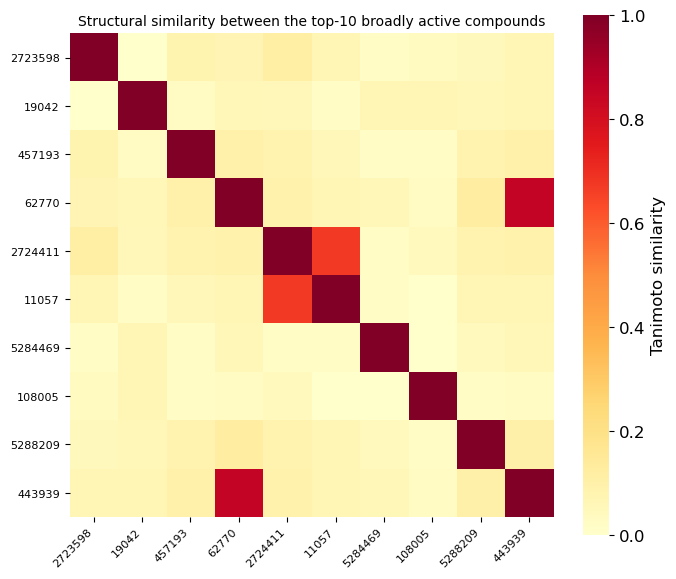

Average pairwise similarity: 0.086
(Values near 0 = structurally diverse; near 1 = almost identical)


In [28]:
import matplotlib.pyplot as plt
import matplotlib

n = len(df)
fps = df['fp'].tolist()
cids = df['PUBCHEM_CID'].tolist()

# Pairwise Tanimoto similarity
sim = np.zeros((n, n))
for i in range(n):
    sim[i] = DataStructs.BulkTanimotoSimilarity(fps[i], fps)

dist = 1 - sim
np.fill_diagonal(dist, 0)

# Plot heatmap
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sim, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels(cids, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(cids, fontsize=8)
plt.colorbar(im, ax=ax, label='Tanimoto similarity')
ax.set_title('Structural similarity between the top-10 broadly active compounds', fontsize=10)
plt.tight_layout()
plt.show()

print(f'Average pairwise similarity: {sim[np.triu_indices(n, k=1)].mean():.3f}')
print('(Values near 0 = structurally diverse; near 1 = almost identical)')

## Step 3
 Maximum Common Substructure (MCS) per Cluster

Largest fragment shared by all compounds in a cluster.  
Large MCS → same scaffold. Tiny/no MCS across clusters → diverse structures, same behavior.

In [29]:
def find_cluster_mcs(cluster_df, sim_matrix, all_idx):
    """For a cluster: find MCS and pick the most representative compound."""
    mols = cluster_df['mol'].tolist()
    scids = cluster_df['PUBCHEM_CID'].tolist()
    idx = cluster_df.index.tolist()

    # Representative = highest average similarity to others in cluster
    if len(mols) == 1:
        rep_i = 0
    else:
        local_idx = [all_idx.index(i) for i in idx]
        sub_sim = sim_matrix[np.ix_(local_idx, local_idx)]
        rep_i = int(sub_sim.mean(axis=1).argmax())

    # MCS
    if len(mols) > 1:
        mcs = rdFMCS.FindMCS(mols, timeout=30,
                             ringMatchesRingOnly=True, completeRingsOnly=True)
        mcs_mol = Chem.MolFromSmarts(mcs.smartsString) if mcs.numAtoms > 0 else None
        mcs_n = mcs.numAtoms
    else:
        mcs_mol = mols[0]
        mcs_n = mols[0].GetNumHeavyAtoms()

    return {
        'rep_mol': mols[rep_i],
        'rep_cid': int(scids[rep_i]),
        'mcs_mol': mcs_mol,
        'mcs_n_atoms': mcs_n,
        'size': len(mols),
        'cids': [int(c) for c in scids],
    }

# Perform hierarchical clustering to assign cluster labels
linkage_matrix = linkage(squareform(dist), method='average')
df['cluster'] = fcluster(linkage_matrix, t=3, criterion='maxclust')  # Adjust 't' as needed

all_idx = df.index.tolist()
cluster_results = {}
for cl in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == cl]
    cluster_results[cl] = find_cluster_mcs(sub, sim, all_idx)

print('MCS summary per cluster:')
print(f'  {"Cluster":>7}  {"Size":>4}  {"MCS atoms":>9}  {"CIDs"}')
print('-' * 60)
for cl, r in cluster_results.items():
    print(f'  {cl:>7}  {r["size"]:>4}  {r["mcs_n_atoms"]:>9}  {r["cids"]}')

MCS summary per cluster:
  Cluster  Size  MCS atoms  CIDs
------------------------------------------------------------
        1     7          6  [2723598, 457193, 62770, 2724411, 11057, 5288209, 443939]
        2     2          1  [19042, 5284469]
        3     1         13  [108005]


## Step 4 — Pairwise MCS for Notable Scaffold-Overlapping Pairs

Two compound pairs show significant shared substructures:
- **2724411 & 11057** — 25-atom shared scaffold
- **62770 & 443939** — 38-atom shared scaffold

Pair 1: CID 2724411 and CID 11057


[20:45:40] Explicit valence for atom # 16 N, 4, is greater than permitted


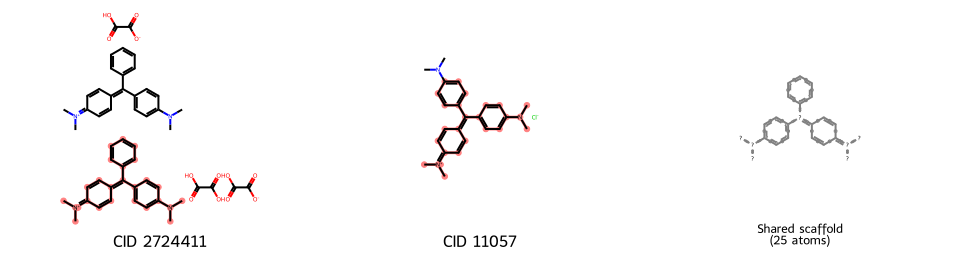

  Pair (2724411, 11057): shared scaffold = 25 heavy atoms

Pair 2: CID 62770 and CID 443939


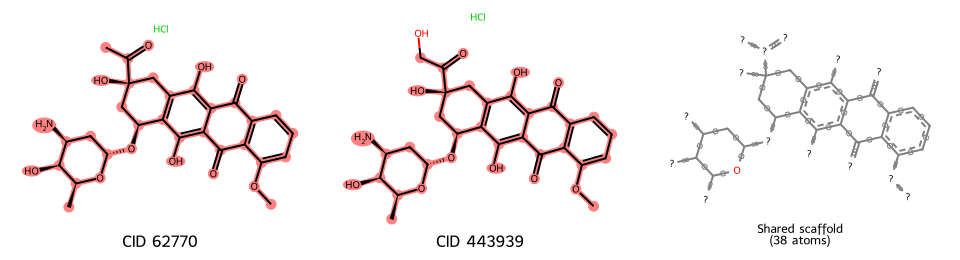

  Pair (62770, 443939): shared scaffold = 38 heavy atoms



In [30]:
def get_mol(cid):
    row = df[df['PUBCHEM_CID'] == cid].iloc[0]
    return row['mol']

def draw_pair_mcs(cid_a, cid_b, label_a=None, label_b=None):
    """Draw two compounds side-by-side with their MCS highlighted."""
    mol_a = get_mol(cid_a)
    mol_b = get_mol(cid_b)

    mcs = rdFMCS.FindMCS(
        [mol_a, mol_b],
        timeout=30,
        ringMatchesRingOnly=True,
        completeRingsOnly=True,
    )
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString) if mcs.numAtoms > 0 else None
    n_atoms = mcs.numAtoms

    # Build highlight atom lists
    def highlight_atoms(mol):
        if mcs_mol is None:
            return []
        match = mol.GetSubstructMatch(mcs_mol)
        return list(match)

    ha_a = highlight_atoms(mol_a)
    ha_b = highlight_atoms(mol_b)

    leg_a = label_a or f'CID {cid_a}'
    leg_b = label_b or f'CID {cid_b}'

    mols_row = [mol_a, mol_b]
    legends_row = [leg_a, leg_b]
    highlights = [ha_a, ha_b]

    if mcs_mol is not None:
        try:
            mcs_draw = Chem.RWMol(mcs_mol)
            Chem.SanitizeMol(mcs_draw)
            mols_row.append(mcs_draw.GetMol())
        except Exception:
            mols_row.append(mcs_mol)
        legends_row.append(f'Shared scaffold\n({n_atoms} atoms)')
        highlights.append([])

    img = Draw.MolsToGridImage(
        mols_row,
        molsPerRow=3,
        subImgSize=(320, 260),
        legends=legends_row,
        highlightAtomLists=highlights,
        returnPNG=False,
    )
    display(img)
    print(f'  Pair ({cid_a}, {cid_b}): shared scaffold = {n_atoms} heavy atoms\n')

# ── Pair 1 ──
print('Pair 1: CID 2724411 and CID 11057')
draw_pair_mcs(2724411, 11057)

# ── Pair 2 ──
print('Pair 2: CID 62770 and CID 443939')
draw_pair_mcs(62770, 443939)

## Step 5 — Representative Structure + Shared Core per Cluster

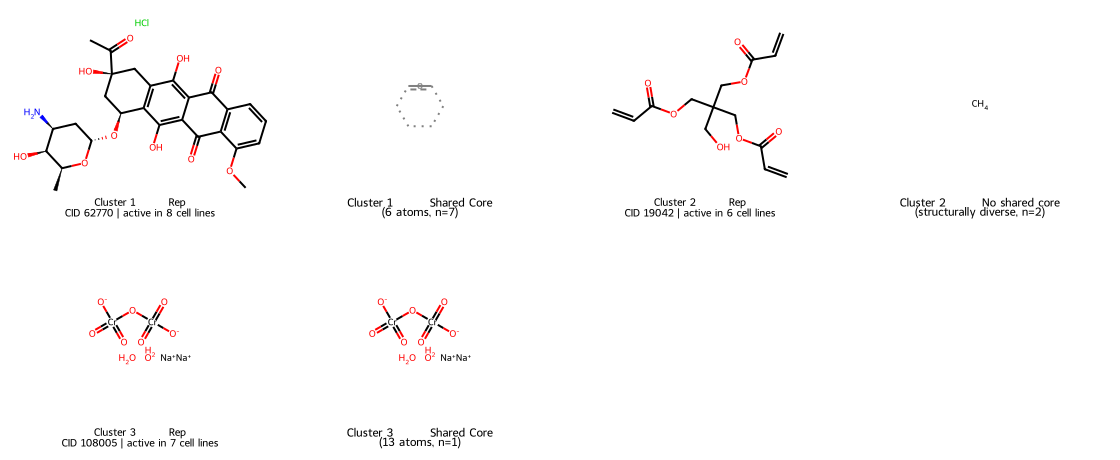

In [31]:
mols_to_draw = []
legends = []

for cl, r in cluster_results.items():
    n_active_vals = df[df['cluster'] == cl]['n_active'].tolist()
    n_active_str = ', '.join(str(x) for x in n_active_vals)

    # Representative
    mols_to_draw.append(r['rep_mol'])
    legends.append(f'Cluster {cl} — Rep\nCID {r["rep_cid"]} | active in {df[df["PUBCHEM_CID"]==r["rep_cid"]]["n_active"].values[0]} cell lines')

    # MCS
    if r['mcs_mol'] is not None and r['mcs_n_atoms'] > 3:
        try:
            mcs_draw = Chem.RWMol(r['mcs_mol'])
            Chem.SanitizeMol(mcs_draw)
            mols_to_draw.append(mcs_draw.GetMol())
        except Exception:
            mols_to_draw.append(r['mcs_mol'])
        legends.append(f'Cluster {cl} — Shared Core\n({r["mcs_n_atoms"]} atoms, n={r["size"]})')
    else:
        mols_to_draw.append(Chem.MolFromSmiles('C'))
        legends.append(f'Cluster {cl} — No shared core\n(structurally diverse, n={r["size"]})')

img = Draw.MolsToGridImage(
    mols_to_draw,
    molsPerRow=min(4, len(mols_to_draw)),
    subImgSize=(280, 230),
    legends=legends,
    returnPNG=False
)
display(img)

In [32]:
#draw the cid of the top 10 structures here 

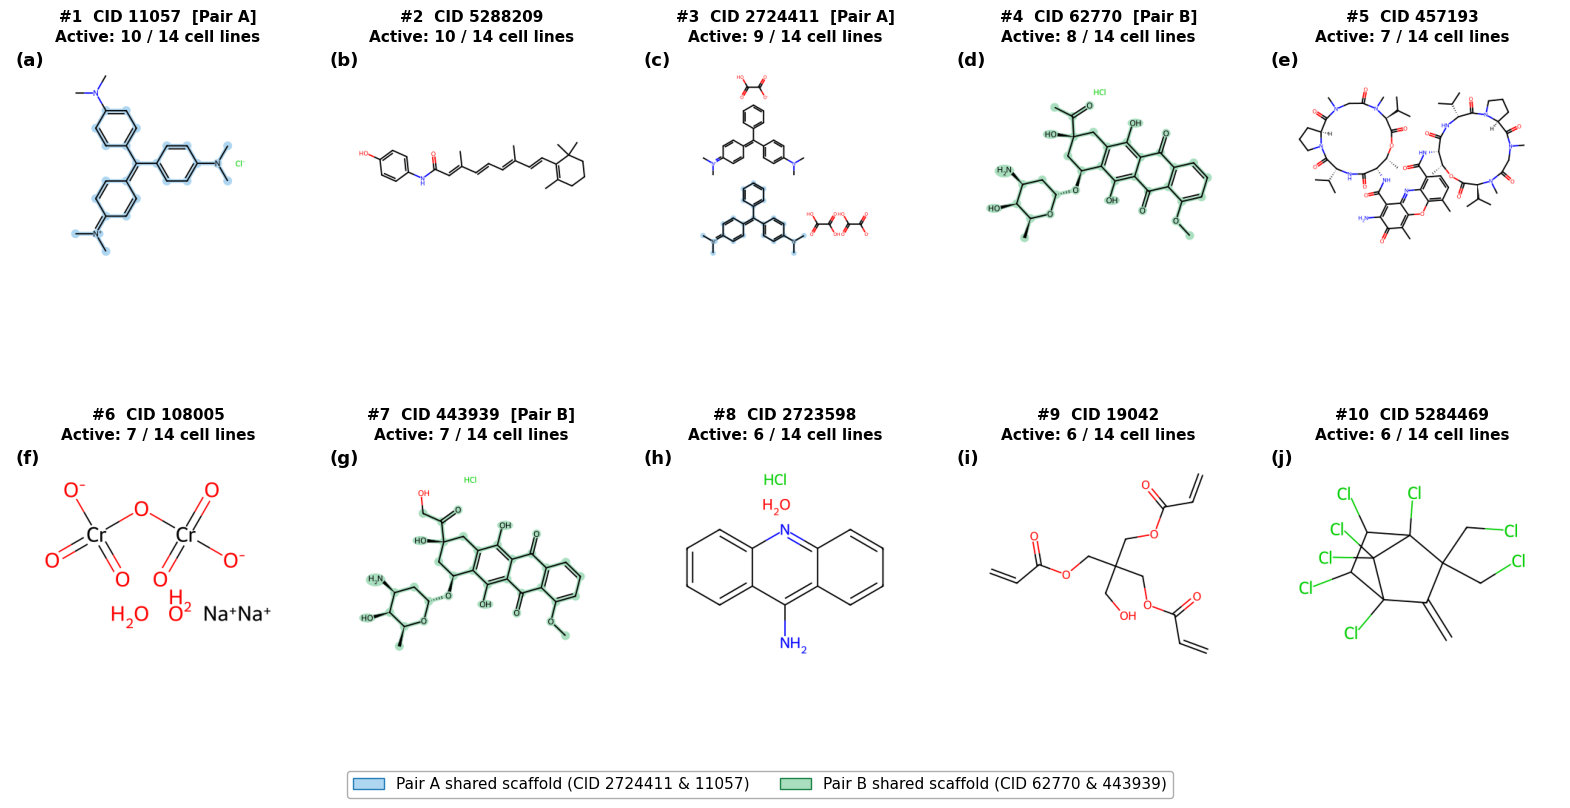

Saved → results/top10_broadly_active_structures.png


In [33]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from rdkit.Chem import Draw, rdFMCS
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import io
import string

# ── Publication style ─────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':  'DejaVu Sans',
    'font.size':    12,
    'axes.linewidth': 0,
    'savefig.dpi':  300,
})

# ── MCS for each pair ─────────────────────────────────────────────────────────
PAIRS = {
    2724411: (11057,  '#AED6F1'),
    11057:   (2724411,'#AED6F1'),
    62770:   (443939, '#A9DFBF'),
    443939:  (62770,  '#A9DFBF'),
}

def compute_mcs_mol(cid_a, cid_b):
    mol_a = df[df['PUBCHEM_CID'] == cid_a]['mol'].values[0]
    mol_b = df[df['PUBCHEM_CID'] == cid_b]['mol'].values[0]
    mcs = rdFMCS.FindMCS([mol_a, mol_b], timeout=30,
                         ringMatchesRingOnly=True, completeRingsOnly=True)
    return Chem.MolFromSmarts(mcs.smartsString), mcs.numAtoms

mcs_A, n_A = compute_mcs_mol(2724411, 11057)
mcs_B, n_B = compute_mcs_mol(62770, 443939)

MOL_SIZE = (400, 320)

def mol_to_pil(mol, highlight_atoms=None, highlight_color=None, size=MOL_SIZE):
    drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    opts = drawer.drawOptions()
    opts.addStereoAnnotation = False
    opts.bondLineWidth = 1.8
    opts.padding = 0.12
    if highlight_atoms:
        color = tuple(int(highlight_color.lstrip('#')[i:i+2], 16) / 255
                      for i in (0, 2, 4))
        atom_colors = {a: color for a in highlight_atoms}
        bond_colors, bond_list = {}, []
        for bond in mol.GetBonds():
            if bond.GetBeginAtomIdx() in highlight_atoms and bond.GetEndAtomIdx() in highlight_atoms:
                bond_list.append(bond.GetIdx())
                bond_colors[bond.GetIdx()] = color
        drawer.DrawMolecule(mol,
                            highlightAtoms=highlight_atoms,
                            highlightAtomColors=atom_colors,
                            highlightBonds=bond_list,
                            highlightBondColors=bond_colors)
    else:
        drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    return Image.open(io.BytesIO(drawer.GetDrawingText()))

# ── Build layout — 5 compounds per row (2 rows) ───────────────────────────────
COLS = 5
top10_ordered = df.sort_values('n_active', ascending=False).reset_index(drop=True)

fig = plt.figure(figsize=(20, 9))
gs = GridSpec(2, COLS, figure=fig, hspace=0.35, wspace=0.06)

panel_labels = list(string.ascii_lowercase)   # a–j

for i, (_, row) in enumerate(top10_ordered.iterrows()):
    r, c = divmod(i, COLS)
    ax = fig.add_subplot(gs[r, c])
    cid = int(row['PUBCHEM_CID'])
    mol = row['mol']

    hl_atoms, hl_color = [], None
    if cid in PAIRS:
        partner  = PAIRS[cid][0]
        hl_color = PAIRS[cid][1]
        ref_mcs  = mcs_A if frozenset([cid, partner]) == frozenset([2724411, 11057]) else mcs_B
        hl_atoms = list(mol.GetSubstructMatch(ref_mcs))

    pil = mol_to_pil(mol, hl_atoms or None, hl_color)
    ax.imshow(pil)
    ax.axis('off')

    ax.text(0.02, 0.98, f'({panel_labels[i]})', transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top', ha='left', color='black')

    rank     = i + 1
    n_active = int(row['n_active'])
    pair_tag = ''
    if cid in [2724411, 11057]:
        pair_tag = '  [Pair A]'
    elif cid in [62770, 443939]:
        pair_tag = '  [Pair B]'

    ax.set_title(f'#{rank}  CID {cid}{pair_tag}\nActive: {n_active} / 14 cell lines',
                 fontsize=11, fontweight='bold', pad=4, linespacing=1.4)

# ── Legend ────────────────────────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(facecolor='#AED6F1', edgecolor='#2980B9',
                   label='Pair A shared scaffold (CID 2724411 & 11057)'),
    mpatches.Patch(facecolor='#A9DFBF', edgecolor='#1E8449',
                   label='Pair B shared scaffold (CID 62770 & 443939)'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=2,
           fontsize=11, frameon=True, framealpha=0.95,
           edgecolor='#AAAAAA', bbox_to_anchor=(0.5, 0.005))

plt.savefig(BASE + 'results/top10_broadly_active_structures.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → results/top10_broadly_active_structures.png')


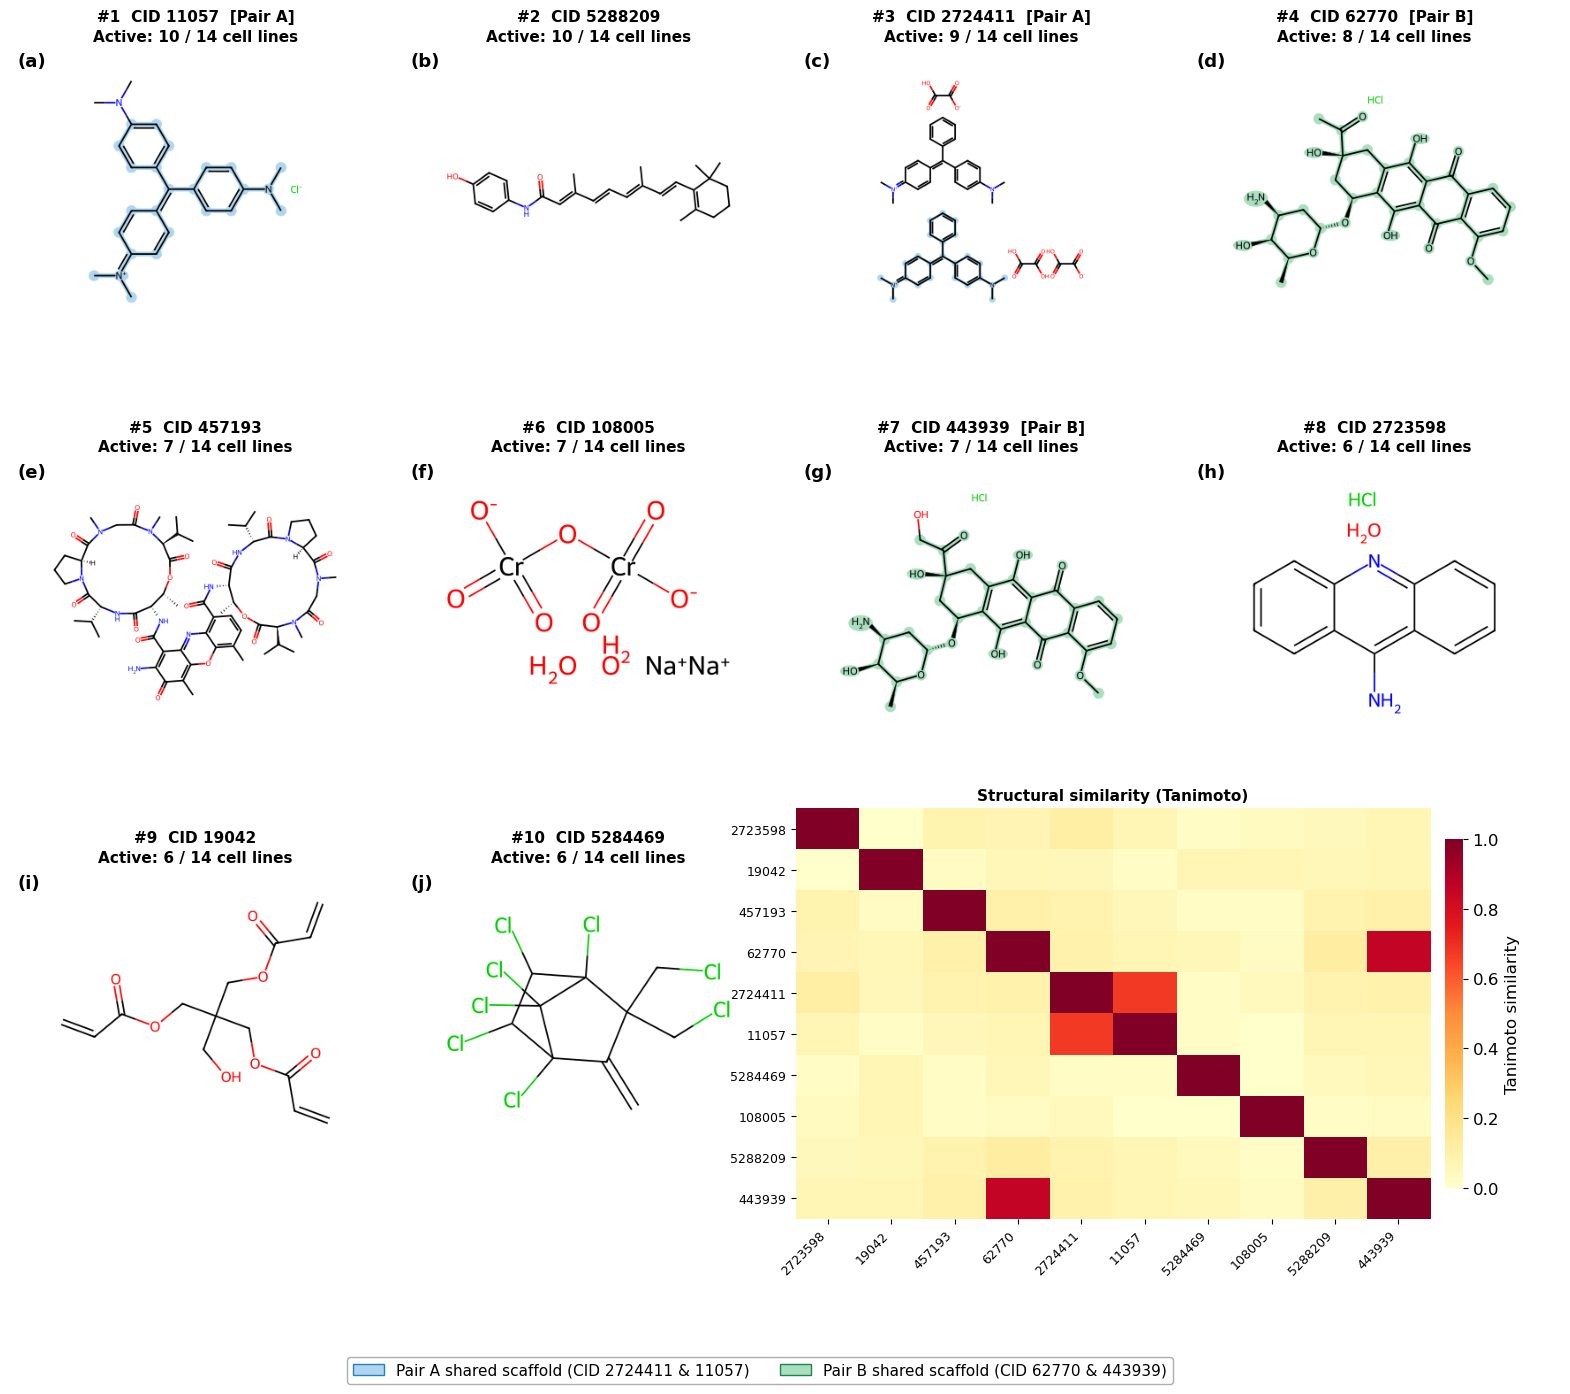

Saved -> results/top10_broadly_active_combined.png


In [44]:
# ── Combined figure: 4 structures/row + heatmap bottom-right ─────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from rdkit.Chem import Draw, rdFMCS
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit import Chem, DataStructs
from PIL import Image
import io, string
import numpy as np

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size":   12,
    "axes.linewidth": 0,
    "savefig.dpi": 300,
})

PAIRS = {
    2724411: (11057,  "#AED6F1"),
    11057:   (2724411,"#AED6F1"),
    62770:   (443939, "#A9DFBF"),
    443939:  (62770,  "#A9DFBF"),
}

def compute_mcs_mol(cid_a, cid_b):
    mol_a = df[df["PUBCHEM_CID"] == cid_a]["mol"].values[0]
    mol_b = df[df["PUBCHEM_CID"] == cid_b]["mol"].values[0]
    mcs = rdFMCS.FindMCS([mol_a, mol_b], timeout=30,
                         ringMatchesRingOnly=True, completeRingsOnly=True)
    return Chem.MolFromSmarts(mcs.smartsString)

mcs_A = compute_mcs_mol(2724411, 11057)
mcs_B = compute_mcs_mol(62770, 443939)

MOL_SIZE = (420, 330)

def mol_to_pil(mol, highlight_atoms=None, highlight_color=None, size=MOL_SIZE):
    drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    opts = drawer.drawOptions()
    opts.addStereoAnnotation = False
    opts.bondLineWidth = 1.8
    opts.padding = 0.12
    if highlight_atoms:
        color = tuple(int(highlight_color.lstrip("#")[i:i+2], 16) / 255 for i in (0, 2, 4))
        atom_colors = {a: color for a in highlight_atoms}
        bond_colors, bond_list = {}, []
        for bond in mol.GetBonds():
            ba, bb = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
            if ba in highlight_atoms and bb in highlight_atoms:
                bond_list.append(bond.GetIdx())
                bond_colors[bond.GetIdx()] = color
        drawer.DrawMolecule(mol,
                            highlightAtoms=highlight_atoms,
                            highlightAtomColors=atom_colors,
                            highlightBonds=bond_list,
                            highlightBondColors=bond_colors)
    else:
        drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    return Image.open(io.BytesIO(drawer.GetDrawingText()))

# ── Sort structures by n_active ───────────────────────────────────────────────
top10_ordered = df.sort_values("n_active", ascending=False).reset_index(drop=True)
n = len(top10_ordered)

# ── Similarity matrix using original df order (matches standalone heatmap) ────
fps_df   = df["fp"].tolist()
cids_plot = df["PUBCHEM_CID"].astype(int).tolist()
n_heat   = len(df)
sim_plot = np.zeros((n_heat, n_heat))
for i in range(n_heat):
    sim_plot[i] = DataStructs.BulkTanimotoSimilarity(fps_df[i], fps_df)

# ── Layout: 3 rows × 4 cols; heatmap fills bottom-right 2 slots ──────────────
mosaic = [
    ["s0", "s1", "s2", "s3"],
    ["s4", "s5", "s6", "s7"],
    ["s8", "s9", "heat", "heat"],
]

fig, axd = plt.subplot_mosaic(
    mosaic, figsize=(20, 16),
    gridspec_kw={"hspace": 0.0, "wspace": 0.06},
)

panel_labels = list(string.ascii_lowercase)

for i, (_, row) in enumerate(top10_ordered.iterrows()):
    ax  = axd[f"s{i}"]
    cid = int(row["PUBCHEM_CID"])
    mol = row["mol"]

    hl_atoms, hl_color = [], None
    if cid in PAIRS:
        partner  = PAIRS[cid][0]
        hl_color = PAIRS[cid][1]
        ref_mcs  = mcs_A if frozenset([cid, partner]) == frozenset([2724411, 11057]) else mcs_B
        hl_atoms = list(mol.GetSubstructMatch(ref_mcs))

    pil = mol_to_pil(mol, hl_atoms or None, hl_color)
    ax.imshow(pil)
    ax.axis("off")
    ax.text(0.02, 0.98, f"({panel_labels[i]})", transform=ax.transAxes,
            fontsize=13, fontweight="bold", va="top", ha="left", color="black")

    rank     = i + 1
    n_active = int(row["n_active"])
    pair_tag = ""
    if cid in [2724411, 11057]:
        pair_tag = "  [Pair A]"
    elif cid in [62770, 443939]:
        pair_tag = "  [Pair B]"

    line1 = f"#{rank}  CID {cid}{pair_tag}"
    line2 = f"Active: {n_active} / 14 cell lines"
    ax.set_title(line1 + "\n" + line2,
                 fontsize=11, fontweight="bold", pad=4, linespacing=1.4)

# ── Heatmap — bottom-right, fills the 2-slot space ───────────────────────────
ax_heat = axd["heat"]
im = ax_heat.imshow(sim_plot, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
ax_heat.set_xticks(range(n))
ax_heat.set_yticks(range(n))
ax_heat.set_xticklabels(cids_plot, rotation=45, ha="right", fontsize=9)
ax_heat.set_yticklabels(cids_plot, fontsize=9)
plt.colorbar(im, ax=ax_heat, label="Tanimoto similarity", shrink=0.85, pad=0.02)
ax_heat.set_title("Structural similarity (Tanimoto)",
                  fontsize=11, fontweight="bold", pad=6)

# ── Legend ────────────────────────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(facecolor="#AED6F1", edgecolor="#2980B9",
                   label="Pair A shared scaffold (CID 2724411 & 11057)"),
    mpatches.Patch(facecolor="#A9DFBF", edgecolor="#1E8449",
                   label="Pair B shared scaffold (CID 62770 & 443939)"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2,
           fontsize=11, frameon=True, framealpha=0.95,
           edgecolor="#AAAAAA", bbox_to_anchor=(0.5, 0.002))

plt.savefig(BASE + "results/top10_broadly_active_combined.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved -> results/top10_broadly_active_combined.png")
